<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# **Visión por Computadora 3D**
# **Clase 1, Experimentando Depth Estimation**

In [ ]:
from transformers import pipeline
from PIL import Image
from google.colab import files
import matplotlib.pyplot as plt

Usamos pipeline de transformers

In [ ]:
estimador = pipeline("depth-estimation", model="Intel/dpt-large")

Loading weights:   0%|          | 0/458 [00:00<?, ?it/s]

[transformers] DPTForDepthEstimation LOAD REPORT from: Intel/dpt-large
Key                                                            | Status  | 
---------------------------------------------------------------+---------+-
neck.fusion_stage.layers.0.residual_layer1.convolution2.weight | MISSING | 
neck.fusion_stage.layers.0.residual_layer1.convolution2.bias   | MISSING | 
neck.fusion_stage.layers.0.residual_layer1.convolution1.weight | MISSING | 
neck.fusion_stage.layers.0.residual_layer1.convolution1.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Subimos una imagen

In [ ]:
subidos = files.upload()
nombre = list(subidos.keys())[0]
imagen = Image.open(nombre).convert("RGB")

Saving images (29).jpeg to images (29) (3).jpeg


In [ ]:
profundidad = estimador(imagen)["depth"]

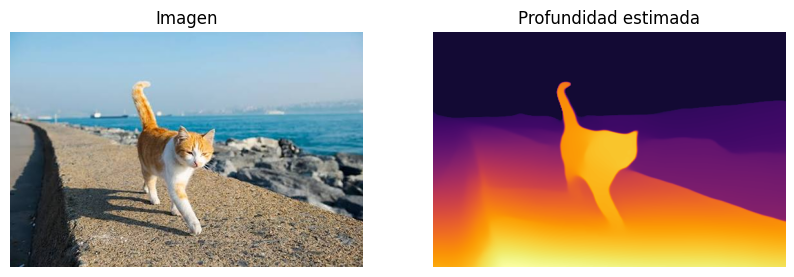

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].imshow(imagen); axs[0].set_title("Imagen")
axs[1].imshow(profundidad, cmap="inferno"); axs[1].set_title("Profundidad estimada")
for ax in axs:
    ax.axis("off")
plt.show()

Ejercicios:
* subir una foto de un pasillo o una calle y verificar si el modelo acierta qué está cerca y qué está lejos

* probar con una foto de una foto, un espejo, un dibujo o una ilusión de perspectiva forzada, como la de sostener la torre de Pisa

* probar con depth-anything/Depth-Anything-V2-Small-hf

* probar con 	depth-anything/Depth-Anything-V2-Base-hf